In [47]:
import keras
from keras.layers import Dense,Dropout,Conv2D,MaxPooling2D,Flatten,BatchNormalization
from keras.models import Sequential
from keras.optimizers import Adam

import tensorflow as tf
import matplotlib.pyplot as plt

In [48]:
!kaggle datasets list | head


ref                                                             title                                                     size  lastUpdated                 downloadCount  voteCount  usabilityRating  
--------------------------------------------------------------  --------------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
datascikhan/e-commerce-sales-and-customer-analytics             E-Commerce Sales Analytics Dataset                    29815424  2026-08-25 08:00:46.013000          12876        279                1  
srisyra02/online-food-ordering-dataset                          Online Food Ordering Dataset                              3648  2026-08-23 15:26:25.483000           9507        155                1  
harishyadav0506/impact-of-social-media-on-life                  Impact of Social Media on Life                           78980  2026-09-09 18:10:54.497000           2325         46                1  


In [49]:
!mkdir -p ~/.kaggle
!echo '{"username":"anushrisane","key":"KGAT_30fd309b43cdffd9e5fba4b01bf93b1f"}' > ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

In [50]:
!kaggle datasets download -d princelv84/dogsvscats

Dataset URL: https://www.kaggle.com/datasets/princelv84/dogsvscats
License(s): MIT
dogsvscats.zip: Skipping, found more recently modified local copy (use --force to force download)


In [51]:
import zipfile
zipref = zipfile.ZipFile('/content/dogsvscats.zip','r')
zipref.extractall('/content')
zipref.close()

# Generators

In [52]:
train_ds=keras.utils.image_dataset_from_directory(
    directory='/content/train',
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(256,256)

)

Found 20000 files belonging to 2 classes.


In [53]:
test_ds=keras.utils.image_dataset_from_directory(
    directory='/content/test',
    label_mode='int',
    labels='inferred',
    image_size=(256,256),
    batch_size=32
)

Found 5000 files belonging to 2 classes.


In [54]:
# which means trasforming our pixel values from 0-255 to 0-1
def process(image,label):
  image = tf.cast(image/255. ,tf.float32)
  return image,label

train_ds = train_ds.map(process)
test_ds = test_ds.map(process)

In [55]:
model=Sequential()

In [56]:
model.add(Conv2D(32,kernel_size=(3,3),padding='valid',activation='relu',input_shape=(256,256,3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(padding='valid',pool_size=(2,2),strides=2))


model.add(Conv2D(64,kernel_size=(3,3),padding='valid',activation='relu',input_shape=(256,256,3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(padding='valid',pool_size=(2,2),strides=2))


model.add(Conv2D(128,kernel_size=(3,3),padding='valid',activation='relu',input_shape=(256,256,3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(padding='valid',pool_size=(2,2),strides=2))


model.add(Flatten())


model.add(Dense(128,activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(64,activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(1,activation='sigmoid'))



/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [57]:
model.compile(metrics=['accuracy'],loss='binary_crossentropy',optimizer='adam')

In [58]:
history=model.fit(train_ds,epochs=10,validation_data=test_ds)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 63s 89ms/step - accuracy: 0.5538 - loss: 1.9351 - val_accuracy: 0.5824 - val_loss: 0.7733
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 58s 93ms/step - accuracy: 0.6230 - loss: 0.6668 - val_accuracy: 0.6966 - val_loss: 0.5689
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 54s 87ms/step - accuracy: 0.6926 - loss: 0.5790 - val_accuracy: 0.7412 - val_loss: 0.5173
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 54s 86ms/step - accuracy: 0.7413 - loss: 0.5315 - val_accuracy: 0.6986 - val_loss: 0.5775
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 83s 87ms/step - accuracy: 0.7664 - loss: 0.4923 - val_accuracy: 0.7766 - val_loss: 0.4773
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 58s 92ms/step - accuracy: 0.8036 - loss: 0.4344 - val_accuracy: 0.7030 - val_loss: 0.5731
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 54s 87ms/step - accuracy: 0.8306 - loss: 0.3936 - val_accuracy: 0.8154 - val_loss: 0.4149
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 53s 85ms/step - accuracy: 0.8613 - loss: 0.3342 - 

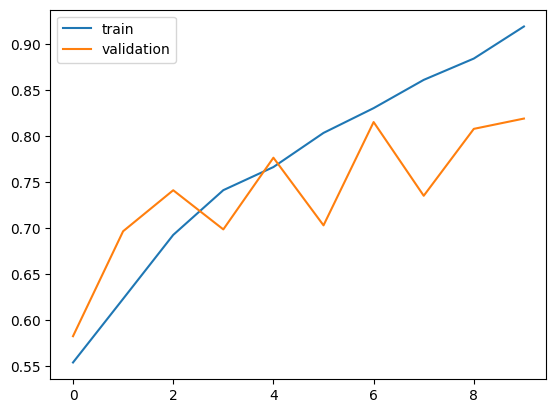

In [59]:
plt.plot(history.history['accuracy'],label='train')
plt.plot(history.history['val_accuracy'],label='validation')
plt.legend()

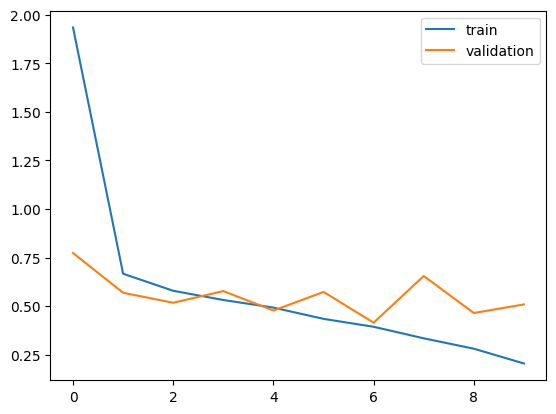

In [60]:
plt.plot(history.history['loss'],label='train')
plt.plot(history.history['val_loss'],label='validation')
plt.legend()

In [61]:
import cv2

cat=1
dog=0

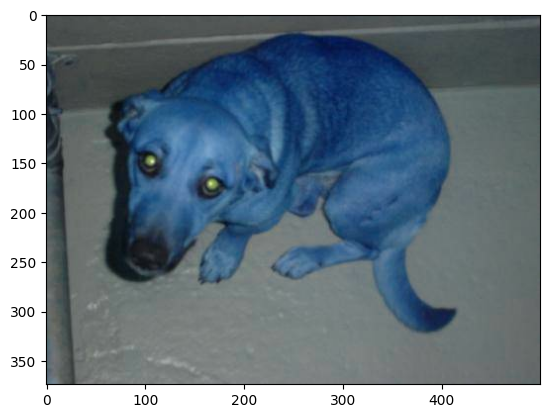

In [62]:
image_test=cv2.imread('/content/test/dogs/dog.10220.jpg')
plt.imshow(image_test)

In [63]:
image_test.shape

(374, 500, 3)

In [64]:
image_test_resize=cv2.resize(image_test,(256,256))

In [65]:
image_test_reshape=image_test_resize.reshape((1,256,256,3))

In [66]:
model.predict(image_test_reshape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 502ms/step


array([[0.]], dtype=float32)

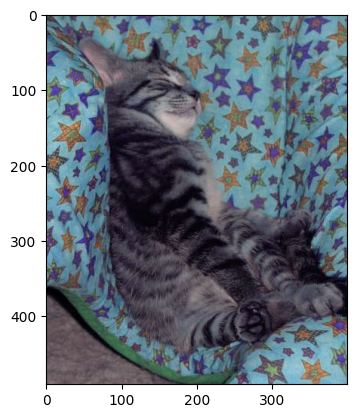

In [67]:
image_test_2=cv2.imread('/content/test/cats/cat.10026.jpg')
plt.imshow(image_test_2)

In [68]:
image_test_2.shape

(491, 400, 3)

In [69]:
image_test_2_resize=cv2.resize(image_test_2,(256,256))

In [70]:
image_test_2_reshape=image_test_2_resize.reshape((1,256,256,3))

In [71]:
model.predict(image_test_2_reshape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


array([[1.]], dtype=float32)

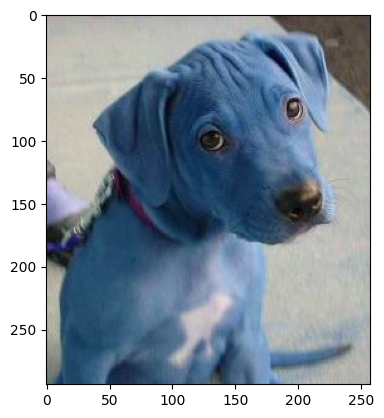

In [72]:
image_test_3=cv2.imread('/content/test/dogs/dog.10126.jpg')
plt.imshow(image_test_3)

In [73]:
image_test_3.shape

(294, 258, 3)

In [74]:
image_test_3_resize=cv2.resize(image_test_3,(256,256))

In [75]:
image_test_3_reshape=image_test_3_resize.reshape((1,256,256,3))

In [76]:
model.predict(image_test_3_reshape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


array([[0.]], dtype=float32)